# Industrial Predictive Maintenance

**Elevvo internship, Industry Level Task 9. Dataset: AI4I 2020 Predictive Maintenance.**

## The problem

A machine failure is expensive, but so is a false alarm: it stops a production line that
was working. So the goal here is not the highest accuracy. It is a failure detector whose
alarms can be trusted.

The measure for that is the **False Discovery Rate (FDR)**: of all the alarms raised, the
share that were false. The rule used throughout this project is

> choose the alarm threshold that catches the most real failures while **at most 5% of
> alarms are false**.

This notebook reads results saved by the project's pipeline. All modelling code lives in
the `pdm` package (`src/pdm/`); nothing is computed by hand here. To regenerate
everything from the raw CSV:

```
python -m pdm.eda
python -m pdm.train
python -m pdm.evaluate
python -m pdm.rul
python -m pdm.report
```

In [1]:
from IPython.display import Image, Markdown, display

from pdm import report
from pdm.config import FIGURES_DIR

m = report.load_metrics()


def show(table):
    display(table.style.hide(axis="index"))


def figure(name):
    display(Image(filename=str(FIGURES_DIR / name)))

## Headline result

In [2]:
Markdown(report.headline(m))

**LightGBM** was selected, with an alarm threshold of 0.75. On the held-out test set it raised 57 alarms, of which 2 were false: a False Discovery Rate of 3.5% (95% interval 0.0% to 8.0%). The estimate is under the 5% cap, but the interval reaches above it. With only 65 test failures, this sample is consistent with the cap being met and does not prove it.

It caught 55 of 65 failures (84.6%) and missed 10. At the default 0.50 threshold the same model raised 64 alarms with 7 false (10.9% FDR) and caught 57. Accuracy was 99.23% at 0.50 and 99.38% at the tuned threshold.

## 1. The data

Each row is one machine cycle with five sensor readings (air temperature, process
temperature, rotational speed, torque, tool wear), a product quality type (L, M, H), a
`Machine failure` flag, and five flags saying which kind of failure it was.

In [3]:
show(report.data_profile(m))

Item,Value
Rows,"10,000"
Missing values,0
Machine failures,339 (3.4%)
Failures with more than one type,24
Failures with no type recorded,9
Random-failure rows labelled healthy,18
Tool runs,120
Median wear when a run ends (min),215
Development rows / failures,"8,049 / 274"
Test rows / failures,"1,951 / 65"


Three things in the data shaped the design.

**Failures are rare.** About 3 rows in 100 are failures, so a model that never raises an
alarm would be about 97% accurate and useless. This is why accuracy is not the headline.

**The failure-type flags are not one-per-row.** Some failures carry two or three types
and a few carry none. "Random failures" are almost never counted as machine failures in
this dataset, and they are random by design, so no model can predict them. Decisions
taken: the `Machine failure` label is used exactly as given, random failures are left out
of the failure-type step, and the failure-type step can report more than one type.

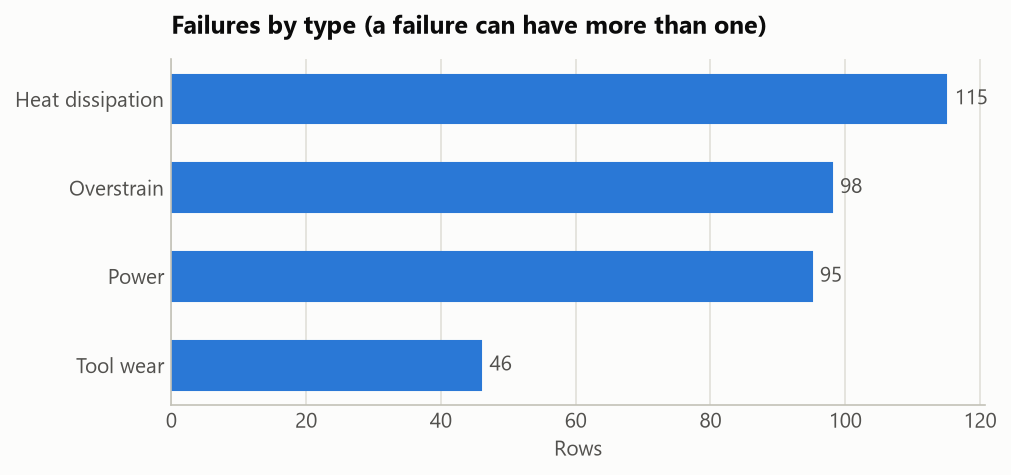

In [4]:
figure("eda_failure_types.png")

**The rows are in time order, grouped into tool runs.** Tool wear climbs a few minutes
per row and drops back to zero when the tool is changed. Rows from the same run resemble
each other, so the data is split by **whole tool runs**: 80% of runs for development and
20% held back as a test set that is used once. Cross-validation folds are also whole
runs. A random row-by-row split would let near-identical neighbours sit on both sides and
make the results look better than they are.

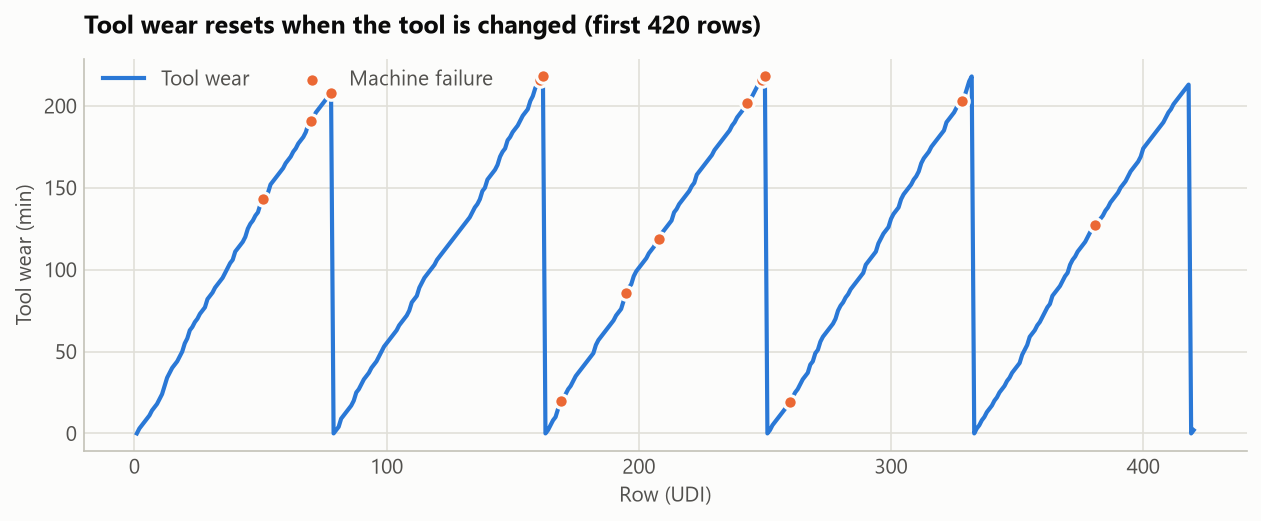

In [5]:
figure("eda_tool_wear_runs.png")

## 2. Which sensor is the lead indicator? (bonus)

Each sensor was compared with each failure flag in three ways: point-biserial
correlation (straight-line link), Spearman correlation (any steadily rising or falling
link) and mutual information (any dependence at all, including "fails at both
extremes"). Only development rows were used.

A caution on wording: the dataset has no timestamps, so this shows which sensor is most
strongly **associated** with failure in the same cycle. It cannot show which sensor
moves first.

In [6]:
show(report.lead_indicator_table(m))

Failure,Failures (dev),Strongest sensor,Its Spearman correlation,Strongest feature overall
Any failure,274,Torque,+0.16,Power
Tool wear,37,Tool wear,+0.11,Tool wear
Heat dissipation,93,Rotational speed,-0.16,Temperature difference
Power,79,Torque,+0.05,Power
Overstrain,75,Tool wear,+0.15,Wear x torque


**Torque is the strongest single sensor for failure overall, with rotational speed
second.** Temperature on its own is the weakest of the three named in the brief.

The per-type view matters more than the overall ranking, because each failure mode has
its own driver:

- **Power failures** follow torque, and even more closely torque x speed (power). Their
  plain correlation with torque is close to zero even though the dependence is strong,
  because power failures happen at both very low and very high power. A correlation
  coefficient alone would have missed this; mutual information catches it.
- **Heat dissipation failures** follow low rotational speed together with a small gap
  between process and air temperature. Temperature matters here as a difference, not as
  a level.
- **Overstrain failures** follow tool wear combined with torque.
- **Tool wear failures** follow tool wear, and only weakly: they happen at an
  unpredictable point late in a tool's life.

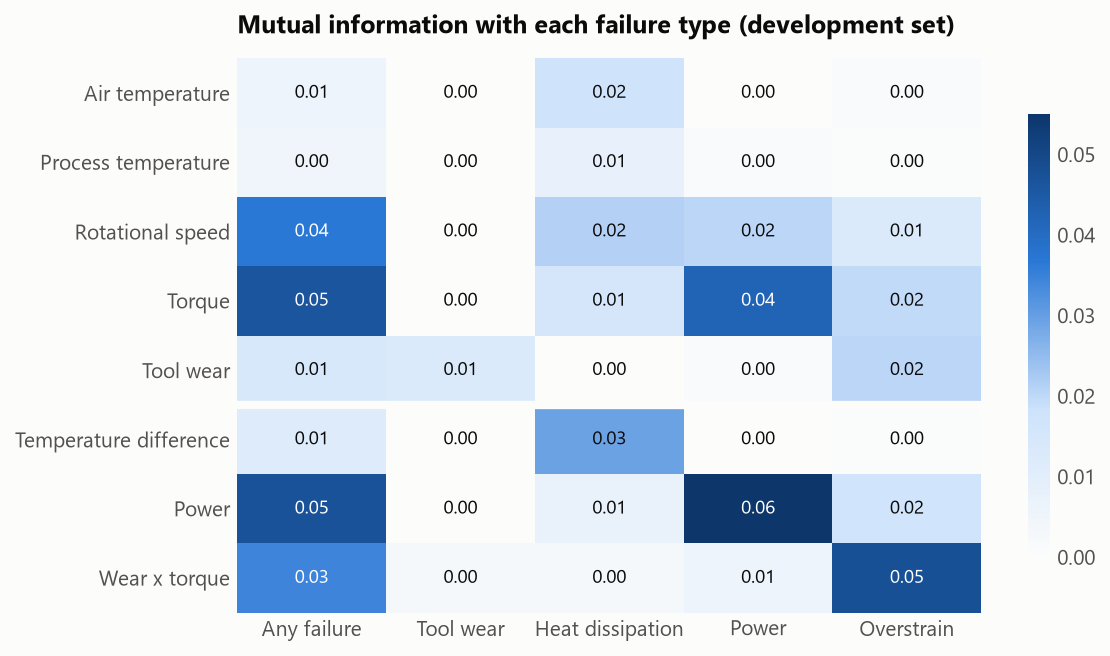

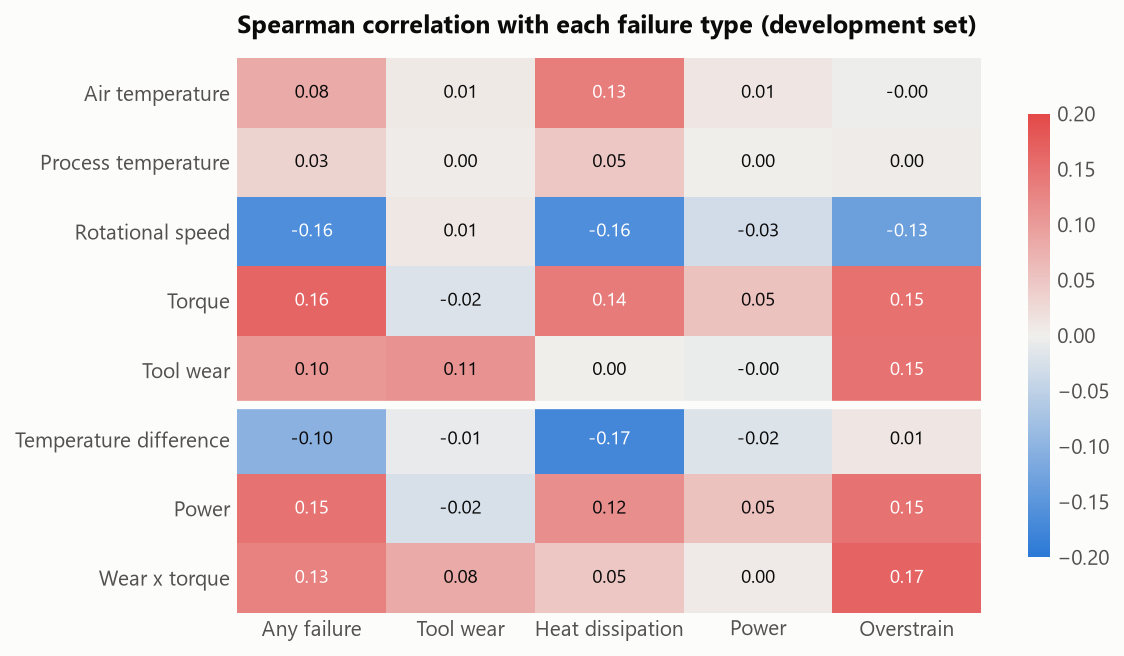

In [7]:
figure("eda_mutual_information.png")
figure("eda_correlation_heatmap.png")

The distributions show the same thing. Failed rows sit at high torque, low speed and
high tool wear, and the engineered features separate the two groups more cleanly than the
raw sensors do.

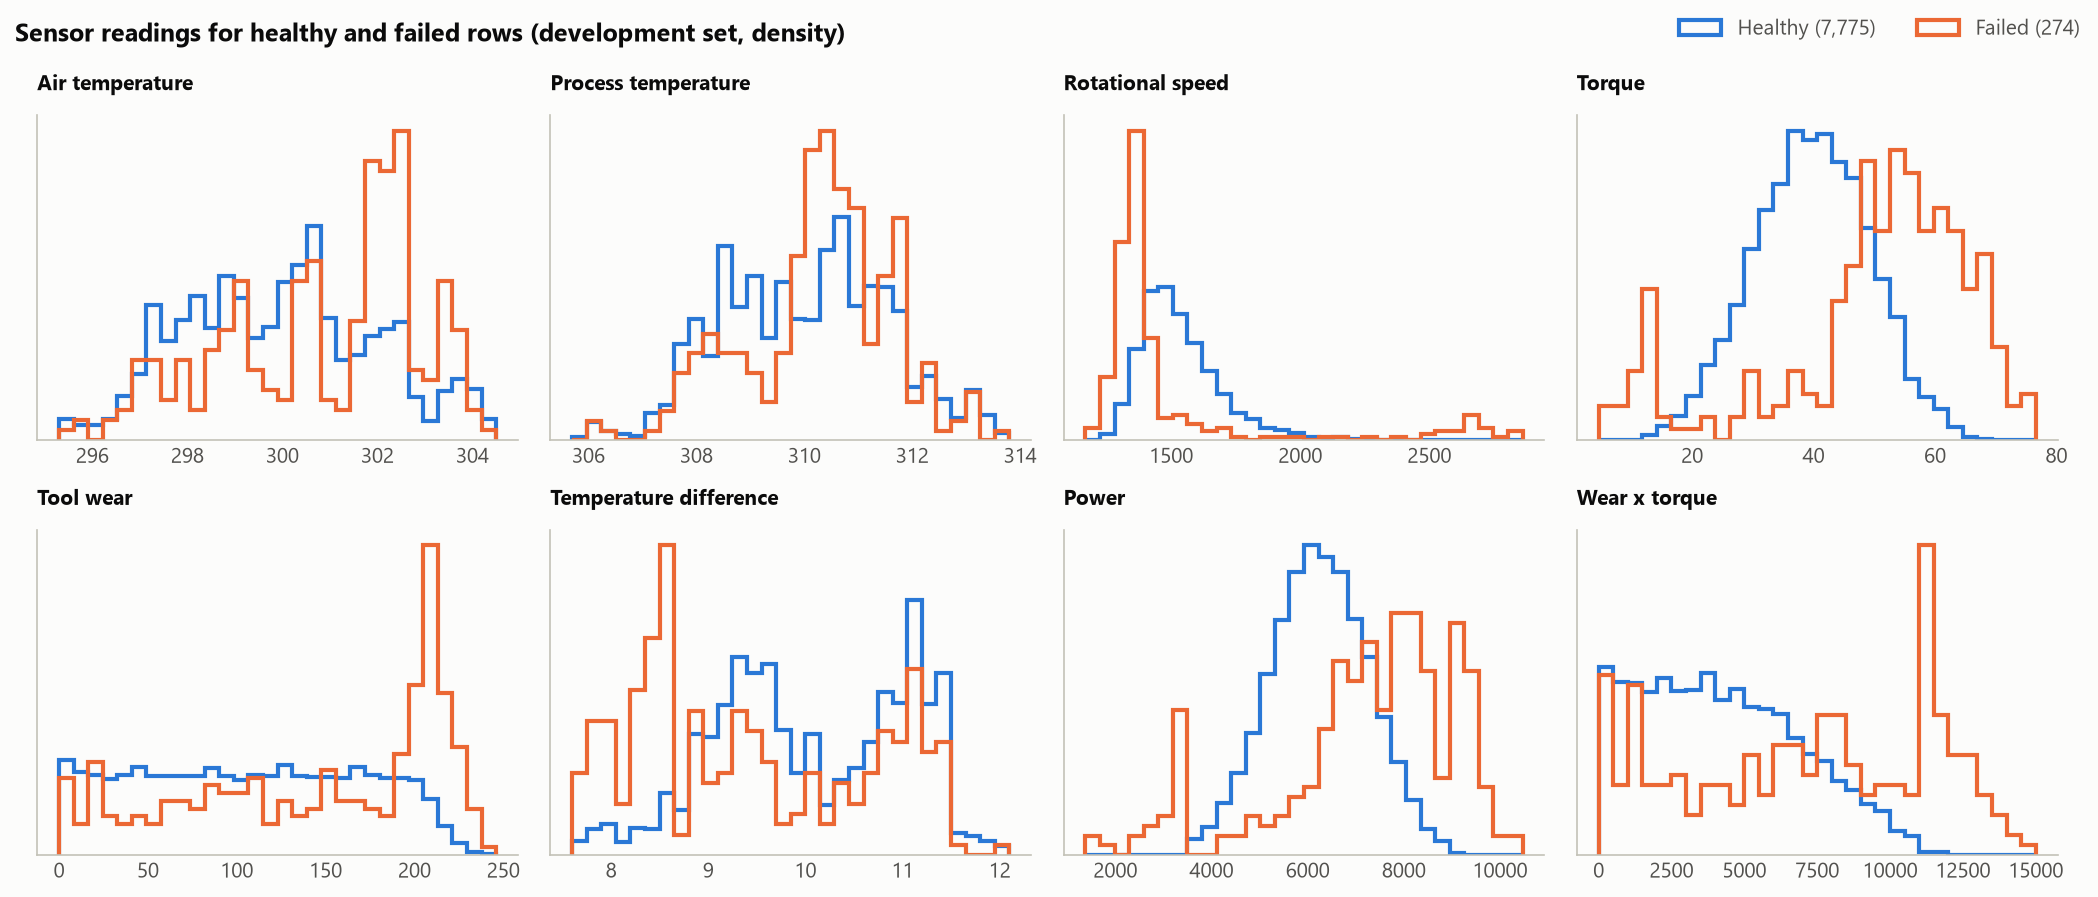

In [8]:
figure("eda_sensor_distributions.png")

These findings gave three engineered features, each computed from a row's own readings:
**power** (torque x rotational speed), **temperature difference** (process minus air)
and **wear x torque**.

## 3. Approach

**Two stages.**

1. **Stage 1, the alarm.** A binary model estimates the probability that a cycle is a
   failure. An alarm is raised when that probability reaches a threshold. Halting the
   line is a yes/no decision, so this is where the False Discovery Rate is measured and
   controlled, with a single threshold.
2. **Stage 2, the diagnosis.** For cycles that raised an alarm, a second model says which
   failure type or types it is: tool wear, heat dissipation, power or overstrain.

**Three model families** were trained for each stage: logistic regression as a simple
baseline, XGBoost and LightGBM.

**Cost-sensitive learning.** Each stage 1 model was trained with three different weights
on the failure class (how much more a missed failure counts than a false alarm during
training). The weight was chosen by the project's actual objective: failures caught at
the 5% cap.

**Choosing the threshold without touching the test set.** Each development row was
scored by a model that had not seen its tool run (5-fold cross-validation by run). The
threshold was picked from those predictions, and the winning model was the one catching
the most failures at its threshold. The test set played no part in any choice.

**Guarding against leakage.** The failure-type flags and the row identifiers are never
model inputs. All scaling and encoding happens inside a pipeline, fitted on training rows
only.

## 4. Results

### How the models compare

In [9]:
show(report.stage1_comparison(m))

Model,Failure weight,Threshold,Dev recall,Dev FDR,Test recall,Test FDR,Test FDR 95% interval,5% cap on test,Test alarms
Logistic regression,1.000000,0.723,14.6%,4.8%,10.8%,22.2%,0.0% to 50.0%,not met,9
XGBoost,1.000000,0.701,74.5%,4.2%,83.1%,1.8%,0.0% to 5.5%,not demonstrable,55
LightGBM,5.000000,0.753,77.7%,4.9%,84.6%,3.5%,0.0% to 8.0%,not demonstrable,57


"Dev" columns are the cross-validated development predictions used to choose the
threshold. They are slightly flattering by construction, because the threshold was picked
on those same predictions to sit just under the cap. "Test" columns are the held-out runs
and are the figures to trust.

The model was chosen on the development columns. The test figures for the other two
models are shown for context only; switching to whichever looks best on test would turn
the test set into a tuning set.

The last column says whether the test result supports the claim that the cap holds:
"met" needs the whole 95% interval under 5%, not only the estimate.

The two boosted models are close, and far ahead of logistic regression, which can only
reach the cap by raising almost no alarms. The failure rules in this data are
combinations of sensors (torque x speed, wear x torque, a temperature gap together with
low speed), which tree models capture and a straight-line model does not.

The curve below shows the trade-off on development data. Moving right catches more
failures; the horizontal line is the cap. Each dot is the chosen threshold.

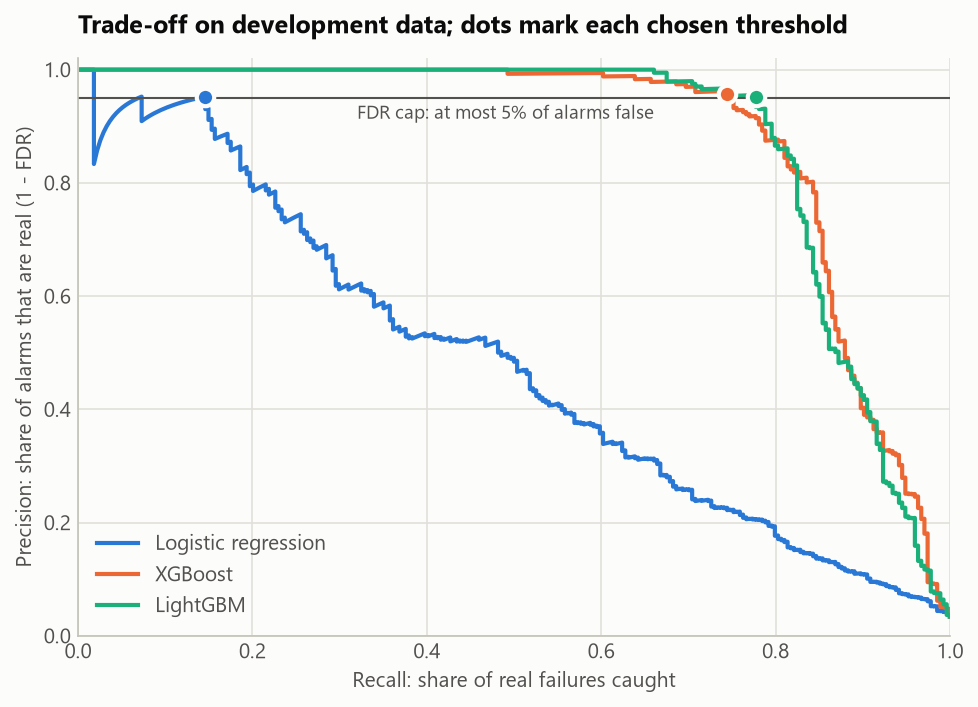

In [10]:
figure("eval_precision_recall.png")

### What the constraint costs

The brief accepts slightly lower accuracy in exchange for fewer false alarms. This is
the winning model on the test set at the usual 0.50 threshold and at the tuned one.

In [11]:
show(report.tradeoff_table(m))

Threshold,Alarms,False alarms,Failures caught,Failures missed,FDR,Recall,Accuracy
Default 0.50,64,7,57,8,10.9%,87.7%,99.23%
Tuned 0.75,57,2,55,10,3.5%,84.6%,99.38%


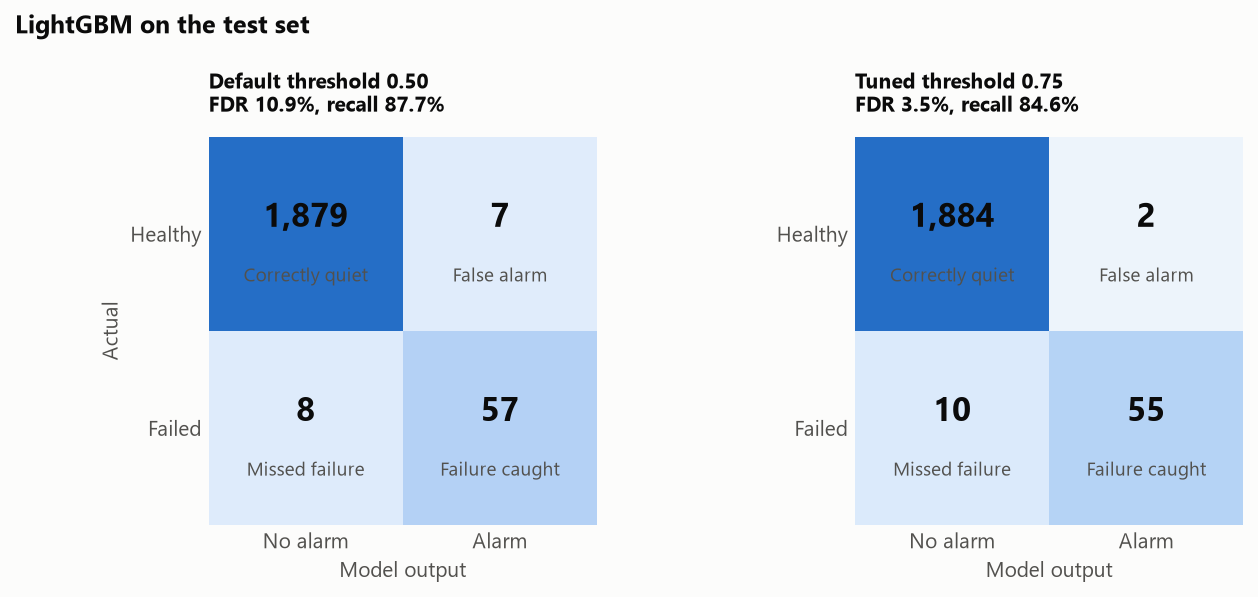

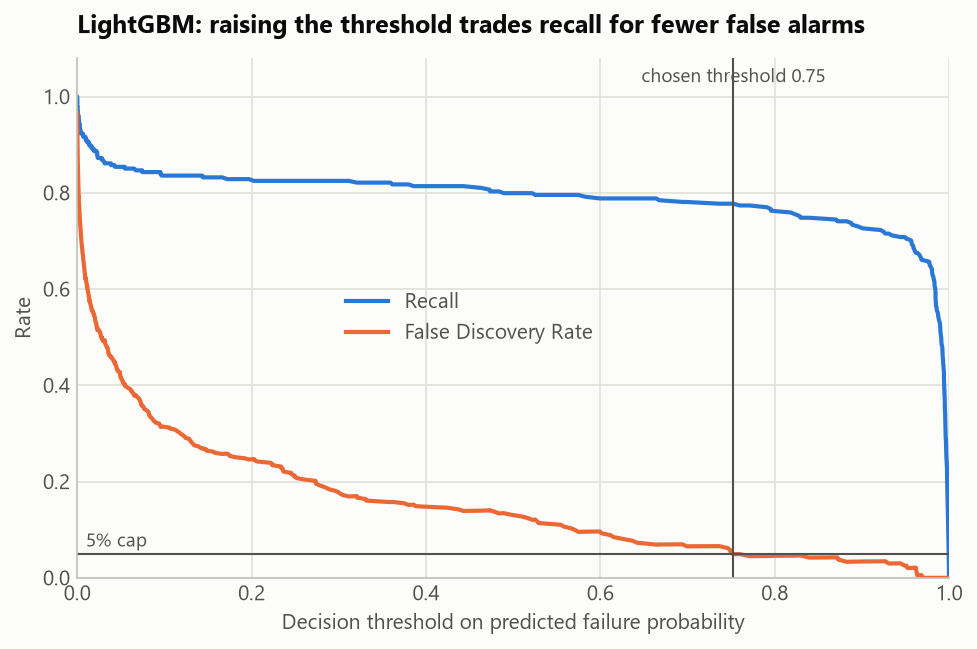

In [12]:
figure("eval_confusion_matrices.png")
figure("eval_threshold_tradeoff.png")

Raising the threshold removed most of the false alarms, and the price was a small number
of additional missed failures. That is the trade the brief asks for.

The brief expects accuracy to drop slightly. Here it did not; it moved slightly the other
way, because the false alarms removed outnumbered the failures newly missed. Accuracy barely registers either change:
with failures this rare, it is dominated by the healthy rows, which is the reason it was
not used to steer the model.

**How sure is the 5% figure?** The test set holds a few dozen failures, so each false
alarm moves the rate by nearly two percentage points. The interval in the comparison
table comes from resampling whole tool runs 2,000 times. Read the test FDR together with
that interval, not as an exact figure.

### What the alarm catches and misses

Overall recall hides a large difference between failure types. A failure with two types
is counted under each.

In [13]:
show(report.caught_by_type_table(m))

Failure type,Test failures,Caught,Missed,Recall
Tool wear,9,1,8,11.1%
Heat dissipation,22,22,0,100.0%
Power,16,16,0,100.0%
Overstrain,23,22,1,95.7%
No type recorded,1,0,1,0.0%


**The alarm is strong on heat dissipation, power and overstrain failures and weak on
tool wear failures.** The first three follow physical rules visible in the sensors. A
tool wear failure happens at an unpredictable moment late in a tool's life, and nothing
in the readings separates the cycle where the tool fails from the cycles just before it.
Nearly all of the missed failures are of this kind. Anyone relying on this model should
know that it is not a tool wear detector; tool changes still need their own schedule.

### Failure type (stage 2)

Scored on the test rows that stage 1 flagged, which is how it would run in practice.

In [14]:
s2 = m["evaluation"]["stage2"]
print(
    f"Stage 2 model: {s2['model']}. Flagged rows: {s2['flagged_rows']} "
    f"({s2['flagged_true_failures']} real failures, {s2['flagged_false_alarms']} false alarms, "
    f"{s2['flagged_failures_without_type']} real failures with no type recorded)."
)
show(report.stage2_table(m))

Stage 2 model: lightgbm. Flagged rows: 57 (55 real failures, 2 false alarms, 0 real failures with no type recorded).


Failure type,Actual,Predicted,Precision,Recall
Tool wear,1,2,50.0%,100.0%
Heat dissipation,22,22,100.0%,100.0%
Power,16,15,100.0%,93.8%
Overstrain,22,25,88.0%,100.0%


Heat dissipation, power and overstrain failures are identified reliably. They follow
physical rules that the model can learn.

Do not read anything into the tool wear row. Stage 1 lets almost no tool wear failures
through, so its percentages rest on one or two rows. These figures are also conditional
on stage 1 raising an alarm: the end-to-end chance of a failure being both flagged and
correctly named is capped by the table in the previous section.

## 5. Time to failure (bonus)

**This is a proxy.** The dataset has no clock, so there is no true "time until failure".
What it does have is tool wear in minutes, which rises through each tool run. The target
is **remaining tool life**: how many more minutes of wear the tool accumulates before its
run ends, either in a tool wear failure or in a replacement. The final run is cut off by
the end of the file and was left out.

In [15]:
display(Markdown(report.rul_headline(m)))
show(report.rul_table(m))

Tools ended their runs between 198 and 253 minutes of wear (average 216). Subtracting current wear from that average predicts remaining life with an average error of 9.2 minutes on the test runs. The learned models did not beat that simple rule: the best one, XGBoost, had an error of 9.7 minutes.

Model,Dev error (min),Test error (min),"Test error, late life (min)"
Average tool life minus wear,7.8,9.2,9.0
XGBoost,8.6,9.7,9.1
LightGBM,8.7,9.9,9.2


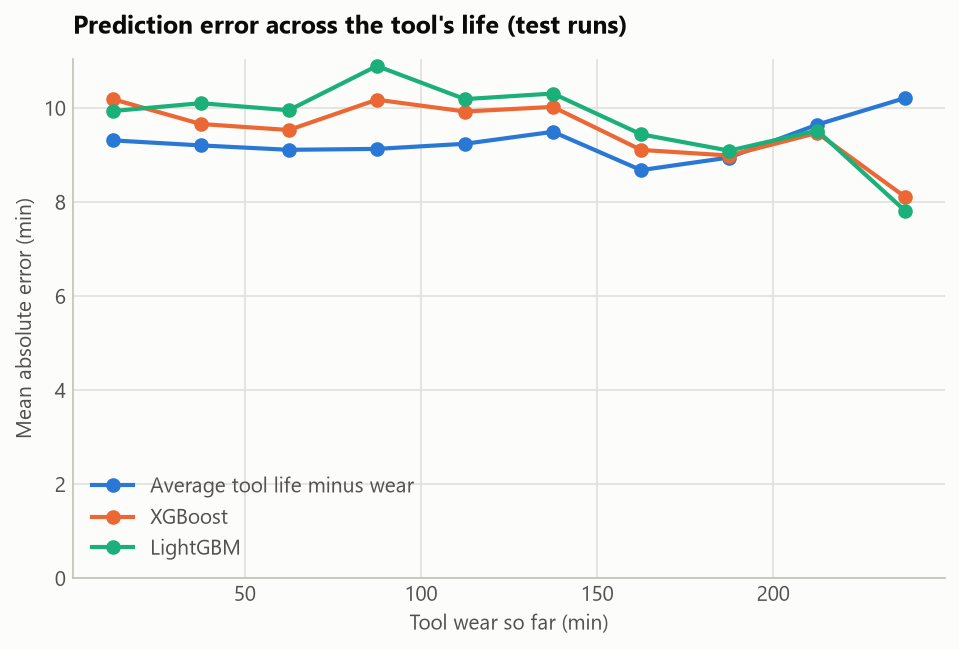

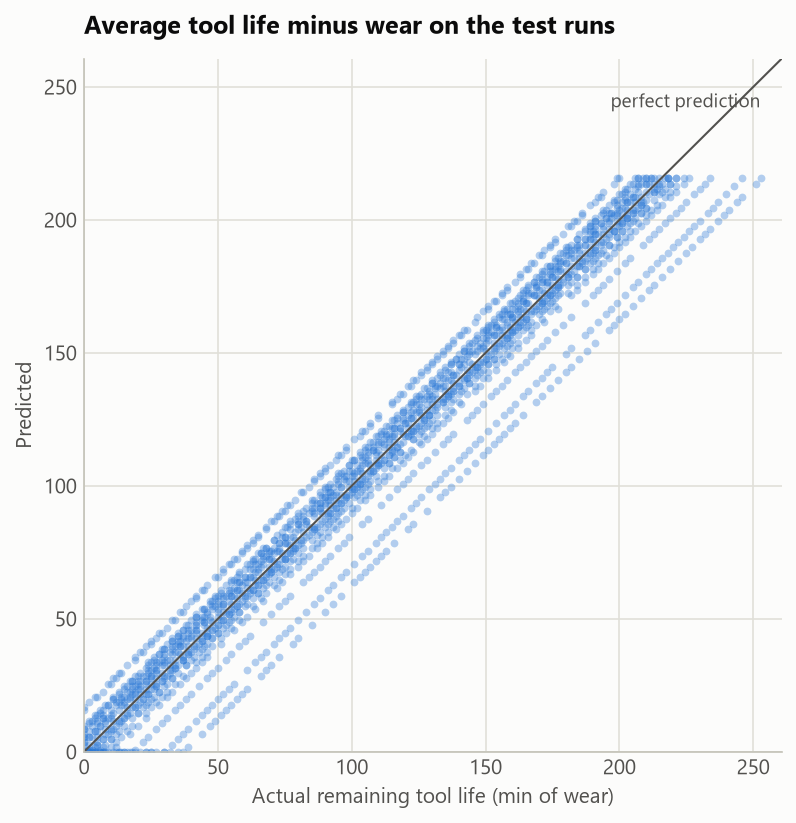

In [16]:
figure("rul_error_by_wear.png")
figure("rul_predicted_vs_actual.png")

**The honest result is that machine learning adds nothing here.** A one-line rule,
average tool life minus current wear, is as good as XGBoost or LightGBM given every
sensor and the run's history.

The reason is in how the data was made. Each tool's run ends at a point that does not
depend on torque, speed or temperature, so those readings carry no information about how
much life is left. The remaining error is the spread of that end point, which no model
can remove. In a real plant, where load and heat do wear tools faster, this could well be
different; it would need real run-to-failure histories with timestamps to find out.

## 6. Limitations

- **The dataset is synthetic.** Its failures follow fixed rules, which is why the
  boosted models do so well. Real sensor data is noisier and performance would be lower.
- **The test set is small.** A few dozen failures give a wide interval around the FDR.
  The cap should be re-checked on more data before anyone relies on it.
- **The threshold sits at the edge of the cap by design**, so on new data the false
  alarm share will land a little above 5% about as often as below. A plant that needs a
  hard guarantee should choose the threshold against a stricter target.
- **Tool wear failures are largely invisible to these sensors** and account for nearly
  all of the missed failures. Random failures are unpredictable by design and are not
  counted as failures by the dataset's own label.
- **The interval understates the uncertainty a little.** It treats the threshold as
  fixed, and the false alarms fall in very few tool runs.
- **No time dimension.** The lead-indicator analysis shows association within a cycle,
  and the time-to-failure model is a proxy built from tool wear.
- **A false alarm and a missed failure are treated only through the 5% rule.** With real
  cost figures for each, the threshold could be set to minimise expected cost instead.